# Chapitre 5 - Cours 2 : splines de lissage, degrés de liberté et choix de $\lambda$

Les splines de régression du cours 1 obligent à choisir le nombre et la position des
nœuds. Les **splines de lissage** contournent ce problème : on met un nœud en **chaque**
observation et l'on contrôle la complexité par une **pénalité** de courbure. Plan :

1. le critère pénalisé et sa solution (§5.4) ;
2. calcul matriciel en base de B-splines, données *bone* (figure 5.6) ;
3. matrice de lissage, degrés de liberté effectifs, forme de Reinsch et valeurs
   propres (§5.4.1, figures 5.7 et 5.8) ;
4. choix de $\lambda$ : compromis biais-variance et validation croisée (§5.5, figure 5.9) ;
5. régression logistique non paramétrique (§5.6).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import (SmoothingSpline, bspline_basis, bspline_penalty_matrix,
                              natural_spline_basis, loocv_score, gcv_score)
set_style()

## 1. Le critère des splines de lissage

Parmi toutes les fonctions $f$ deux fois dérivables, on cherche celle qui minimise la
**somme des carrés résiduels pénalisée** (éq. (5.9) du livre)

$$
\mathrm{RSS}(f, \lambda) = \sum_{i=1}^{N}\{y_i - f(x_i)\}^2
  + \lambda \int \{f''(t)\}^2\,dt .
$$

Le premier terme mesure l'**attache aux données**, le second la **courbure** de $f$
($f''$ est nulle pour une droite). Le paramètre $\lambda \ge 0$ règle le compromis :

- $\lambda = 0$ : aucune pénalité, $f$ peut être n'importe quelle fonction interpolant
  les données ;
- $\lambda = \infty$ : aucune courbure tolérée, $f$ est la droite des moindres carrés.

**Théorème (exercice 5.7).** Le problème, posé sur un espace de fonctions de dimension
infinie, admet une solution **unique**, qui est une **spline cubique naturelle** dont les
nœuds sont les valeurs distinctes des $x_i$.

> **Intuition.** Fixons les valeurs $f(x_i) = z_i$. Le premier terme ne dépend plus que
> des $z_i$ ; il reste à minimiser $\int f''^2$ parmi les fonctions qui passent par les
> points $(x_i, z_i)$ : c'est la spline cubique naturelle interpolante qui réalise ce
> minimum (exercice 5.7). On peut donc se restreindre à cet espace de dimension $N$.

## 2. Forme matricielle

Écrivons $f(x) = \sum_{j} N_j(x)\theta_j$ dans une base de cet espace. Avec
$\{\mathbf N\}_{ij} = N_j(x_i)$ et $\{\Omega_N\}_{jk} = \int N_j''(t)N_k''(t)\,dt$, on a
$\int f''^2 = \theta^T\Omega_N\theta$ (par bilinéarité de l'intégrale), donc (éq. (5.11))

$$
\mathrm{RSS}(\theta, \lambda) = (\mathbf y - \mathbf N\theta)^T(\mathbf y - \mathbf N\theta)
  + \lambda\,\theta^T\Omega_N\theta .
$$

Le gradient en $\theta$ vaut $-2\mathbf N^T(\mathbf y - \mathbf N\theta) + 2\lambda\Omega_N\theta$ ;
l'annuler donne (éq. (5.12))

$$
\hat\theta = (\mathbf N^T\mathbf N + \lambda\Omega_N)^{-1}\mathbf N^T\mathbf y ,
$$

une **régression ridge généralisée**. En pratique (annexe du chapitre, éq. (5.79)), on
travaille dans une base de **B-splines cubiques** : la pénalité impose d'elle-même la
linéarité aux bords, et les matrices sont creuses.

> **Remarque (implémentation).** La classe `SmoothingSpline` de `esl.ch05_splines` place
> les nœuds intérieurs aux valeurs distinctes $x_{(2)}, \dots, x_{(n-1)}$ et les nœuds de
> bord en $x_{(1)}$ et $x_{(n)}$ : c'est une base de $n + 2$ B-splines (exercice 5.8).
> La matrice $\Omega_B$ est calculée **exactement** : $B_j''$ est affine sur chaque
> intervalle entre nœuds, donc $B_j''B_k''$ est un polynôme de degré 2, intégré exactement
> par une quadrature de Gauss à 2 points.

Vérifions sur un exemple que $\gamma^T\Omega_B\gamma = \int f''^2$ pour
$f = \sum_j \gamma_j B_j$, en comparant à une intégration numérique fine.

In [2]:
rng = np.random.RandomState(0)
noeuds = np.sort(rng.uniform(0, 1, 8))
Om = bspline_penalty_matrix(noeuds, 0.0, 1.0)
gam = rng.randn(Om.shape[0])
tt = np.linspace(0, 1, 200001)
f2 = bspline_basis(tt, noeuds, 0.0, 1.0, deriv=2) @ gam
print("gamma^T Omega gamma  =", gam @ Om @ gam)
print("intégrale numérique  =", np.trapezoid(f2 ** 2, tt))

gamma^T Omega gamma  = 32731.739399694183
intégrale numérique  = 32731.739272045375


Le noyau de $\Omega_B$ (vecteurs $\gamma$ tels que $\gamma^T\Omega_B\gamma = 0$) correspond
aux fonctions de dérivée seconde nulle, c'est-à-dire aux **fonctions affines** : il est de
dimension 2.

In [3]:
vp = np.linalg.eigvalsh(Om)
print("plus petites valeurs propres de Omega :", np.round(vp[:4], 6) + 0.0)

plus petites valeurs propres de Omega : [  0.         0.        27.179188 211.390231]


## 3. Exemple : densité minérale osseuse (figure 5.6)

La réponse est la variation relative de la densité minérale osseuse (DMO) de la colonne
vertébrale chez des adolescents, mesurée entre deux visites, en fonction de l'âge. On
ajuste une spline de lissage séparément aux garçons et aux filles, avec **12 degrés de
liberté effectifs** (notion définie au §4 ci-dessous).

In [4]:
bone = datasets.load_bone()
print(bone.groupby("gender").agg(n=("age", "size"), ages_distincts=("age", "nunique"),
                                 age_min=("age", "min"), age_max=("age", "max")))

          n  ages_distincts  age_min  age_max
gender                                       
female  259             168      9.4    25.55
male    226             152      9.6    25.20


In [5]:
fits = {}
for g in ["male", "female"]:
    d = bone[bone["gender"] == g]
    fits[g] = SmoothingSpline(df=12).fit(d["age"].to_numpy(), d["spnbmd"].to_numpy())
    etendue = d["age"].max() - d["age"].min()
    print("%-6s : lambda = %.4f (échelle des âges), lambda/étendue^3 = %.6f, ddl = %.2f"
          % (g, fits[g].lam_, fits[g].lam_ / etendue ** 3, fits[g].df_))

male   : lambda = 0.8443 (échelle des âges), lambda/étendue^3 = 0.000222, ddl = 12.00
female : lambda = 1.0545 (échelle des âges), lambda/étendue^3 = 0.000250, ddl = 12.00


Le $\lambda$ dépend de l'échelle de $x$ : si l'on remplace $x$ par $x/s$, la dérivée
seconde est multipliée par $s^2$ et $dt$ par $1/s$, donc $\int f''^2$ est multiplié par
$s^3$. En ramenant les âges dans $[0, 1]$ (comme le fait le logiciel utilisé dans le
livre), on trouve $\lambda \approx 0{,}00022$ pour les garçons, la valeur annoncée dans
la légende de la figure 5.6.

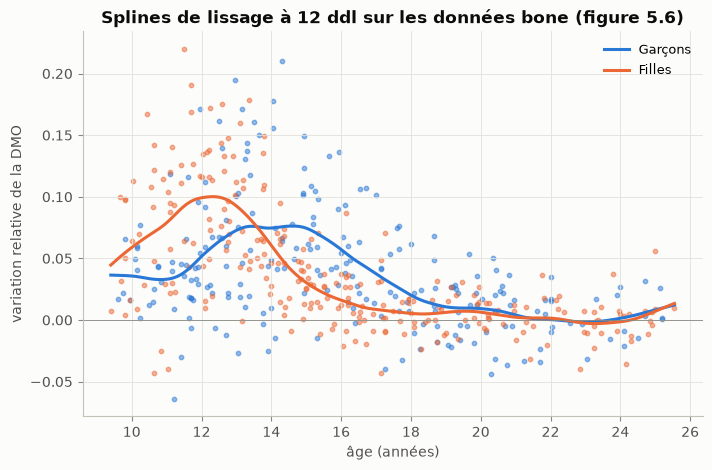

In [6]:
age_grid = np.linspace(bone["age"].min(), bone["age"].max(), 400)
noms = {"male": "Garçons", "female": "Filles"}
plt.figure(figsize=(8, 5))
for c, g in zip([BLUE, ORANGE], ["male", "female"]):
    d = bone[bone["gender"] == g]
    plt.scatter(d["age"], d["spnbmd"], s=10, color=c, alpha=0.5)
    plt.plot(age_grid, fits[g].predict(age_grid), color=c, lw=2.2, label=noms[g])
plt.axhline(0, color=GRAY, lw=0.6)
plt.xlabel("âge (années)")
plt.ylabel("variation relative de la DMO")
plt.title("Splines de lissage à 12 ddl sur les données bone (figure 5.6)")
plt.legend()
plt.show()

In [7]:
for g in ["male", "female"]:
    pic = age_grid[np.argmax(fits[g].predict(age_grid))]
    print("%-8s : pic de croissance osseuse vers %.1f ans" % (noms[g], pic))

Garçons  : pic de croissance osseuse vers 14.6 ans
Filles   : pic de croissance osseuse vers 12.3 ans


> **À retenir.** Ce résumé simple confirme que le pic de croissance des filles précède
> celui des garçons d'environ deux ans.

## 4. Matrice de lissage et degrés de liberté effectifs (§5.4.1)

Le vecteur des valeurs ajustées $\hat{\mathbf f} = (\hat f(x_i))_i$ s'écrit (éq. (5.14))

$$
\hat{\mathbf f} = \mathbf N(\mathbf N^T\mathbf N + \lambda\Omega_N)^{-1}\mathbf N^T\mathbf y
  = \mathbf S_\lambda\,\mathbf y .
$$

C'est un **lisseur linéaire** : $\mathbf S_\lambda$ (la *matrice de lissage*) ne dépend que
des $x_i$ et de $\lambda$, pas de $\mathbf y$. Comparons-la à la matrice de projection
d'une spline de régression à $M$ fonctions de base (éq. (5.15)) :
$\mathbf H_\xi = \mathbf B_\xi(\mathbf B_\xi^T\mathbf B_\xi)^{-1}\mathbf B_\xi^T$.

- Les deux sont **symétriques semi-définies positives**.
- $\mathbf H_\xi^2 = \mathbf H_\xi$ (projection) tandis que
  $\mathbf S_\lambda^2 \preceq \mathbf S_\lambda$ : la différence
  $\mathbf S_\lambda - \mathbf S_\lambda^2$ est semi-définie positive (*rétrécissement*).
- $\mathbf H_\xi$ est de rang $M$, $\mathbf S_\lambda$ de rang $N$.

Pour étudier $\mathbf S_\lambda$, prenons les filles en gardant **une seule observation
par âge** : les $x_i$ sont alors distincts et $\mathbf S_\lambda$ est inversible.

In [8]:
fem = bone[bone["gender"] == "female"].drop_duplicates("age").sort_values("age")
xf, yf = fem["age"].to_numpy(), fem["spnbmd"].to_numpy()
Nf = len(xf)
ss12 = SmoothingSpline(df=12).fit(xf, yf)
S = ss12.smoother_matrix()
kn = np.quantile(xf, np.linspace(0, 1, 10))[1:-1]          # 8 nœuds -> 12 fonctions
Bx = bspline_basis(xf, kn, xf.min(), xf.max())
Hx = Bx @ np.linalg.solve(Bx.T @ Bx, Bx.T)
print("N =", Nf, " | trace(S) = %.2f, trace(H) = %.2f" % (np.trace(S), np.trace(Hx)))

N = 168  | trace(S) = 12.00, trace(H) = 12.00


In [9]:
def resume(M, nom):
    vp = np.linalg.eigvalsh(M)
    vp2 = np.linalg.eigvalsh(M - M @ M)
    print("%s : sym. %s | vp dans [%.2e, %.4f] | rang %d | min vp(M - M^2) = %.1e"
          % (nom, np.allclose(M, M.T), vp.min(), vp.max(),
             np.linalg.matrix_rank(M, tol=1e-10), vp2.min()))

resume(S, "S_lambda")
resume(Hx, "H_xi    ")
print("||H^2 - H|| =", np.abs(Hx @ Hx - Hx).max())

S_lambda : sym. True | vp dans [4.15e-06, 1.0000] | rang 168 | min vp(M - M^2) = -6.8e-16
H_xi     : sym. True | vp dans [-6.94e-16, 1.0000] | rang 12 | min vp(M - M^2) = -1.1e-15
||H^2 - H|| = 4.996003610813204e-16


### Degrés de liberté effectifs

Pour la projection, $\mathrm{tr}(\mathbf H_\xi) = M$ est le nombre de paramètres. Par
analogie, on définit les **degrés de liberté effectifs** d'une spline de lissage par
(éq. (5.16))

$$
\mathrm{df}_\lambda = \mathrm{tr}(\mathbf S_\lambda) .
$$

C'est une fonction **strictement décroissante** de $\lambda$, de $N$ (interpolation)
à 2 (droite). On peut donc spécifier la quantité de lissage par $\mathrm{df}_\lambda$,
plus parlant que $\lambda$, puis retrouver $\lambda$ numériquement (§5.5.1).

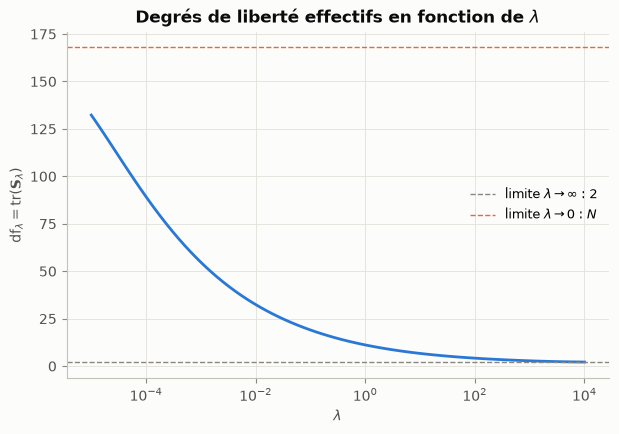

In [10]:
lams = np.logspace(-5, 4, 80)
dfs = [SmoothingSpline(lam=l).fit(xf, yf).df_ for l in lams]
plt.figure(figsize=(7, 4.5))
plt.semilogx(lams, dfs, color=BLUE)
plt.axhline(2, color=GRAY, ls="--", lw=1, label="limite $\\lambda\\to\\infty$ : 2")
plt.axhline(Nf, color=ORANGE, ls="--", lw=1, label="limite $\\lambda\\to 0$ : $N$")
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\mathrm{df}_\lambda = \mathrm{tr}(\mathbf{S}_\lambda)$")
plt.title("Degrés de liberté effectifs en fonction de $\\lambda$")
plt.legend()
plt.show()